# Module 7 Lab 3
Titanic data - Build a classifier for survival from the titanic using kNN or shallow decision tree.

Steps
+ Import database
+ Investigate and clean database (eg 177 missing ages, assn text suggest impute with median or mean, defend your choice...and...change sex encoding to 1 or 2 instead of male or female)
+ Pick 2–4 numeric-ready features (class, age, sex encoded as 0/1, fare) as predictor attributes
+ Split the data 70/30
+ Train the model
+ Test the model
+ Optional: predict on titanic_test.csv


In [1]:
#Import Libraries
import pandas as pd
import seaborn as sns
import numpy as np
import scipy
import matplotlib.pyplot as plt
import statsmodels.api as sm
import sklearn

In [2]:
#Import database
original_df = pd.read_csv('titanic_train.csv')
df=original_df

In [3]:
df.shape

(891, 12)

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
print(df.duplicated().sum())

0


In [8]:
df['Survived'].sum()

np.int64(342)

In [9]:
count = 0
for value in df['SibSp']:
    if value > 0:
        count = count + 1
print(count)

283


In [10]:
df['Age'].median()

np.float64(28.0)

# Database notes
+ Using sum(), I find that 342 of the 891 passengers survived (yes = 1, no = 0).
+ Cabin Number: 687 of 891 missing - I will remove this column and assume class will suffice as a classifier. Assume better class means better egress access so cabin number is not relevant. 
+ Ages - 177 ages missing - Q1, Q3 range is 20 to 38 years old. Mean is 30, median is 28. These numbers are very close so it is not skewed toward the young or the old. I will replace the missing ages with the median, although in this case wither would be a defensible option.

# Prediciting attributes for this assignment
Based on the database notes above, I will select class of ticket, age, sex, SibSp as my predicting attributes for survival.

In [11]:
#Replace missing ages with median age
df['Age'] = df['Age'].fillna(df['Age'].median())

In [12]:
#Check replacements
count = 0
for value in df['Age']:
    if value > 0:
        count = count + 1
print(count)

891


In [13]:
#Change sex data type from string to numeric
df['Sex'] = df["Sex"].map({"male": 0, "female": 1})

In [14]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,NaN,S


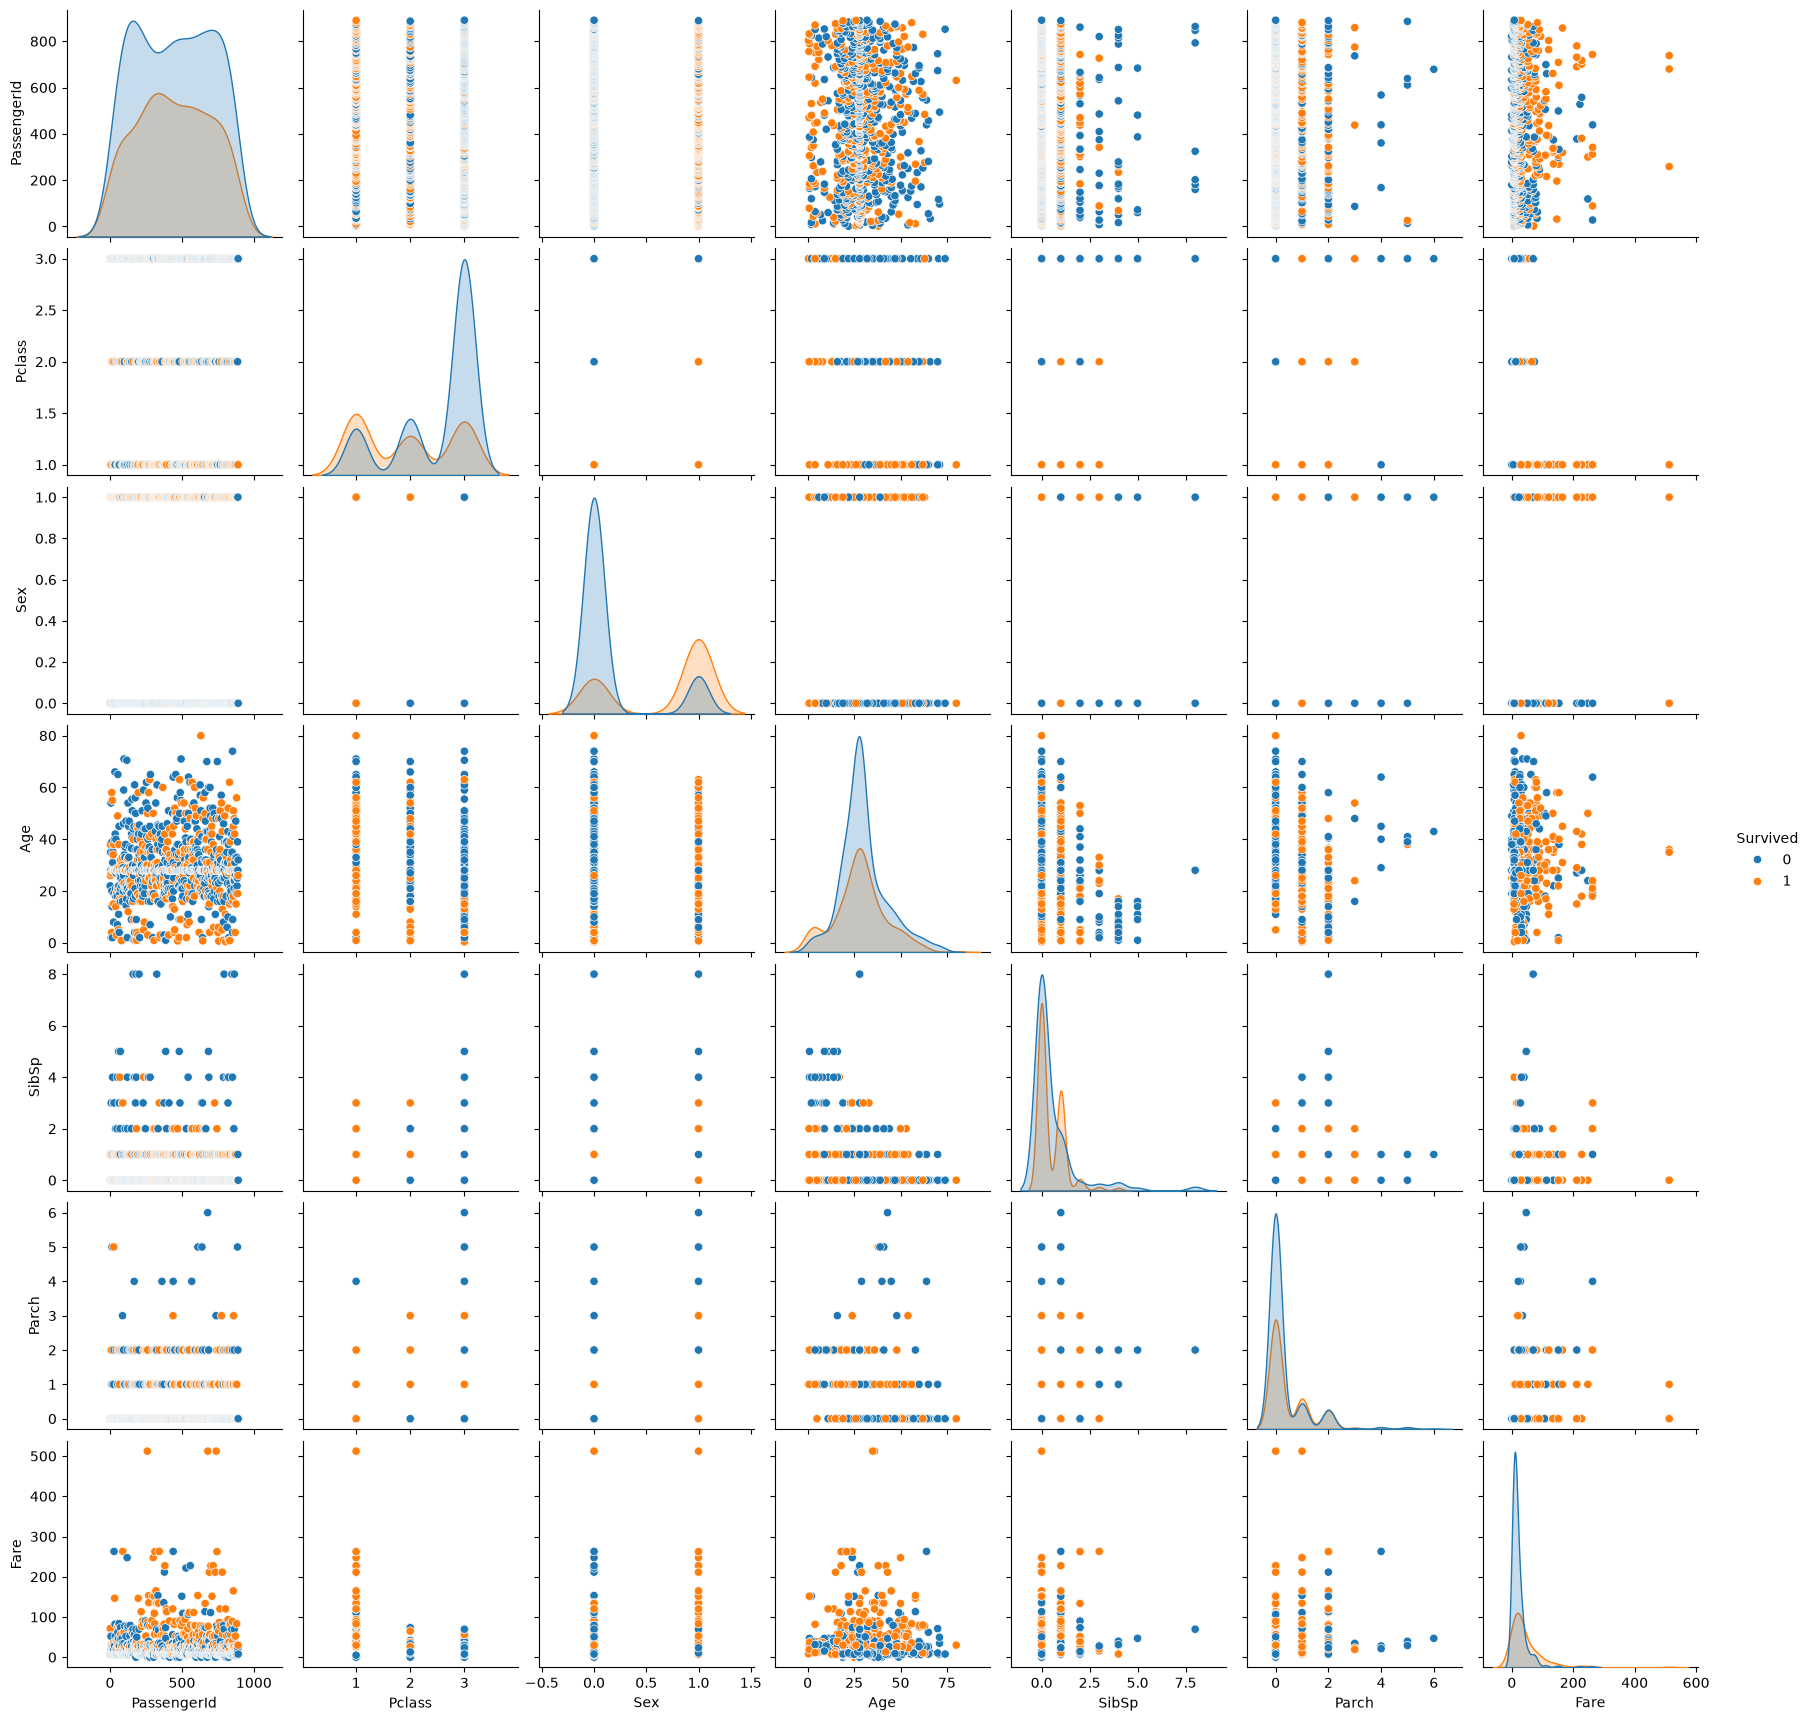

In [15]:
#Create scatterplot (code from video https://www.youtube.com/watch?v=CaRcRk2c8bM)

sns.pairplot(data=df, hue = 'Survived')
plt.show()

#Split Data and Assign predicting attributes and target fields

In [16]:
# Assign predicting attributes and target
from sklearn.model_selection import train_test_split
X = df[["Pclass", "Age", "Sex"]] # Features
y = df["Survived"] # Target


#set the seed (from text)
np.random.seed(1223)
ind=np.random.choice([1,2],size=len(df),replace=True,p=[0.7,0.3])

#Split into training and test data
X_train = X[ind == 1]
X_test = X[ind == 2]

#Identify "survived" as the target variable
y_train = y[ind == 1]
y_test = y[ind == 2]

#Convert to factor vectors
y_train = pd.factorize(y_train)[0]
y_test = pd.factorize(y_test)[0]

In [17]:
#Confirm split
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (609, 3)
y_train shape: (609,)
X_test shape: (282, 3)


In [18]:
#Assignment text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree #added based on video viewed
knn = KNeighborsClassifier(n_neighbors=5)
tree = DecisionTreeClassifier(max_depth=3)

In [19]:
#Now build kNN model (from book)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

knn_classifier = KNeighborsClassifier(n_neighbors=5)
dtree = DecisionTreeClassifier(max_depth=3)

knn_classifier.fit(X_train, y_train)
y_pred = knn_classifier.predict(X_test)

unique, frequency = np.unique(y_pred, return_counts = True)
print(unique)
print(frequency)

[0 1]
[186  96]


In [20]:
# Accuracy test (from video)
from sklearn.metrics import accuracy_score, confusion_matrix
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy of the model:{accuracy*100:.2f}%")

Accuracy of the model:24.47%


In [21]:
#Check acccuracy with pandas (from book)
cross_df = pd.DataFrame({'X_pred': y_pred, 'X.testLabels':y_test})
cross_tab = pd.crosstab(cross_df['X_pred'], cross_df['X.testLabels'], margins=True)
print(cross_tab)

X.testLabels    0    1  All
X_pred                     
0              44  142  186
1              71   25   96
All           115  167  282


# Confusion Matrix Outcome
264 predictions were made. There were 142 correct predictions for not surviving and 65 correct predictions that the would survive. 207 of the 264 predictions were correct, 78.5 percent.

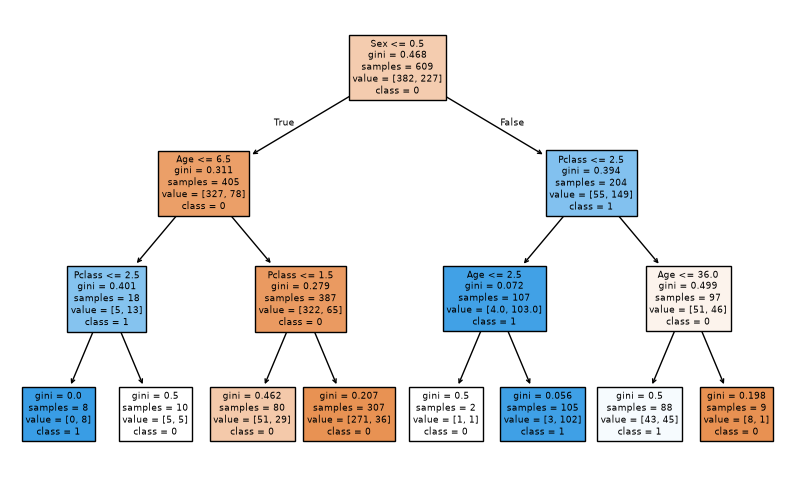

In [22]:
#Decision Tree Plot (AI help for the class string coding section)

dtree.fit(X_train, y_train)

from sklearn.tree import plot_tree
plt.figure(figsize=(10,6))
plot_tree(dtree, 
          feature_names=X.columns, 
          class_names=[str(c) for c in dtree.classes_], 
          filled=True)
plt.show()

# Fit Statement
I chose to use Pclass, sex, age, and SibSp as my predicting attributes. My model has a 24% accuracy. The decision tree first sorts by sex. Men then get sorted by age (<=6.5) then Pclass. The women are sorted by Pclass then age. But the tree does not make sense. 

In [23]:
#Import titanic_test database as predict_df
predict_df = pd.read_csv('titanic_test.csv')

In [24]:
predict_df.shape

(418, 11)

In [25]:
predict_df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [26]:
predict_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 52.8 KB


In [27]:
#Replace missing ages with median age
predict_df['Age'] = predict_df['Age'].fillna(df['Age'].median())

In [28]:
#Check replacements
count = 0
for value in predict_df['Age']:
    if value > 0:
        count = count + 1
print(count)

418


In [29]:
#change sex data type
#Change sex data type from string to numeric
predict_df['Sex'] = predict_df["Sex"].map({"male": 0, "female": 1})

In [30]:
predict_df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",0,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",1,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",0,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",0,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",1,22.0,1,1,3101298,12.2875,NaN,S


#Check predictions using titanic_test
X = predict_df[["Pclass", "Age", "Sex"]] # Features
y = predict_df["Survived"] # Target
test_cross_df = pd.DataFrame({'X_pred': y_pred, 'X.testLabels':y_test})
cross_tab = pd.crosstab(test_cross_df['X_pred'], test_cross_df['X.testLabels'], margins=True)
print(cross_tab)

In [31]:
#That did not work so I asked AI how to test predictions

# 1. Select the exact same features from your test dataframe
X_predict = predict_df[["Pclass", "Age", "Sex"]]

# 2. Use your trained model (e.g., dtree or knn_classifier) to predict
test_predictions = dtree.predict(X_predict)

# 3. Create a clean results DataFrame with PassengerId and their predicted survival
submission_df = pd.DataFrame({
    'PassengerId': predict_df['PassengerId'],
    'Survived': test_predictions
})

In [32]:
submission_df.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [33]:
# Now I can join the dataframes and the submission data frame can be checked for accuracy if the data in known

https://github.com/acamend/cs82a-portfolio